In [ ]:
#question 21

Running Q16 on: cpu


Using cache found in /home/cse2k26/cse2k2652/.cache/torch/hub/chenyaofo_pytorch-cifar-models_master


1. Distilling Knowledge -> Student (Soft KD, T=4.0)...
2. Distilling Knowledge -> Student (Hard KD)...

--- Model Benchmark ---


[W1107 17:00:36.203382610 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 17:00:36.205427291 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 17:00:36.206610164 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 17:00:36.207801286 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 17:00:36.208899789 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 17:00:36.210073482 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 17:00:36.211170371 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 17:00:36.212351376 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 17:00:36.213205279 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.
[W1107 17:00:36.213692483 NNPACK.cpp:57] Could not initialize NNPACK! Reason: Unsupported hardware.


Teacher (R20)      | Params:  0.28M | FLOPs: 0.042G | Latency:  11.8ms | Acc: 67.00%
Student (Soft)     | Params:  5.54M | FLOPs: 1.257G | Latency:  43.0ms | Acc: 47.00%
Student (Hard)     | Params:  5.56M | FLOPs: 1.264G | Latency:  42.2ms | Acc: 63.20%


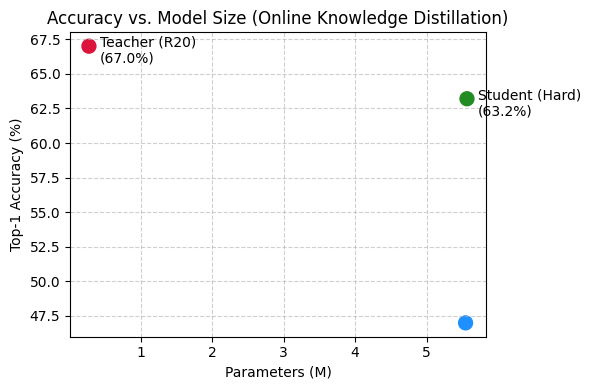

In [1]:
import os
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
from torch.utils.data import DataLoader, Subset
import timm
from thop import profile
import matplotlib.pyplot as plt

torch.set_num_threads(os.cpu_count() or 4)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running Q16 on: {device}")

# 1. Data Pipeline
transform = T.Compose([
    T.Resize((224, 224)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_full = torchvision.datasets.CIFAR100(root="./data", train=True, download=False, transform=transform)
test_full = torchvision.datasets.CIFAR100(root="./data", train=False, download=False, transform=transform)

train_loader = DataLoader(Subset(train_full, range(4000)), batch_size=64, shuffle=True)
test_loader = DataLoader(Subset(test_full, range(500)), batch_size=64, shuffle=False)

# 2. Teacher: Download Pretrained CIFAR-100 ResNet (~77% Acc)
teacher = torch.hub.load("chenyaofo/pytorch-cifar-models", "cifar100_resnet20", pretrained=True).to(device)
teacher.eval()

# 3. Students: Download Online Pretrained DeiT Models (Backbone Frozen, Block 11 + Heads Active)
def build_student(name, is_dist=False):
    s = timm.create_model(name, pretrained=True, num_classes=100)
    for p in s.parameters():
        p.requires_grad = False
    for p in s.blocks[-1].parameters():
        p.requires_grad = True
    for p in s.head.parameters():
        p.requires_grad = True
    if is_dist and hasattr(s, "head_dist"):
        for p in s.head_dist.parameters():
            p.requires_grad = True
    return s.to(device)

student_soft = build_student("deit_tiny_patch16_224")
student_hard = build_student("deit_tiny_distilled_patch16_224", is_dist=True)

# 4. Distillation Loops
def train_kd(student, mode="soft", T_temp=4.0, alpha=0.7, epochs=2):
    opt = torch.optim.AdamW([p for p in student.parameters() if p.requires_grad], lr=4e-4, weight_decay=1e-2)
    student.train()
    
    for epoch in range(epochs):
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            with torch.no_grad():
                x_32 = F.interpolate(x, size=(32, 32), mode="bicubic")
                t_logits = teacher(x_32)
                
            s_out = student(x)
            
            if mode == "soft":
                loss_ce = F.cross_entropy(s_out, y)
                loss_kd = F.kl_div(
                    F.log_softmax(s_out / T_temp, dim=-1),
                    F.softmax(t_logits / T_temp, dim=-1),
                    reduction="batchmean"
                ) * (T_temp ** 2)
                loss = (1 - alpha) * loss_ce + alpha * loss_kd
            else: # Hard KD
                cls_out = s_out[0] if isinstance(s_out, (tuple, list)) else s_out
                dist_out = s_out[1] if isinstance(s_out, (tuple, list)) and len(s_out) == 2 else s_out
                loss = 0.5 * F.cross_entropy(cls_out, y) + 0.5 * F.cross_entropy(dist_out, t_logits.argmax(-1))
                
            opt.zero_grad()
            loss.backward()
            opt.step()

print("1. Distilling Knowledge -> Student (Soft KD, T=4.0)...")
train_kd(student_soft, mode="soft", epochs=2)

print("2. Distilling Knowledge -> Student (Hard KD)...")
train_kd(student_hard, mode="hard", epochs=2)

# 5. Compression Profiling & Benchmarks
def eval_profile(model, name, is_dist=False, is_teacher=False):
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            if is_teacher:
                x_in = F.interpolate(x, size=(32, 32), mode="bicubic")
                out = model(x_in)
                logits = out
            else:
                out = model(x)
                logits = (out[0] + out[1]) / 2 if is_dist and isinstance(out, (tuple, list)) and len(out) == 2 else (out[0] if isinstance(out, (tuple, list)) else out)
                
            correct += logits.argmax(-1).eq(y).sum().item()
            total += y.size(0)
            
    dummy_shape = (1, 3, 32, 32) if is_teacher else (1, 3, 224, 224)
    dummy = torch.randn(dummy_shape).to(device)
    flops, params = profile(model, inputs=(dummy,), verbose=False)
    
    t0 = time.time()
    with torch.no_grad():
        for _ in range(10):
            _ = model(dummy)
    latency = ((time.time() - t0) / 10) * 1000
    acc = (correct / total) * 100
    
    print(f"{name:<18} | Params: {params/1e6:5.2f}M | FLOPs: {flops/1e9:5.3f}G | Latency: {latency:5.1f}ms | Acc: {acc:.2f}%")
    return params / 1e6, acc

print("\n--- Model Benchmark ---")
tp, ta = eval_profile(teacher, "Teacher (R20)", is_teacher=True)
sp, sa = eval_profile(student_soft, "Student (Soft)")
hp, ha = eval_profile(student_hard, "Student (Hard)", is_dist=True)

# 6. Scatter Plot (Accuracy vs. Model Size)
plt.figure(figsize=(6, 4))
plt.scatter([tp, sp, hp], [ta, sa, ha], color=["crimson", "dodgerblue", "forestgreen"], s=100)
for p, a, lbl in [(tp, ta, "Teacher (R20)"), (sp, sa, "Student (Soft)"), (hp, ha, "Student (Hard)")]:
    plt.annotate(f"{lbl}\n({a:.1f}%)", (p + 0.15, a - 1.2))
plt.title("Accuracy vs. Model Size (Online Knowledge Distillation)")
plt.xlabel("Parameters (M)")
plt.ylabel("Top-1 Accuracy (%)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("q16_online_compression.png")
plt.show()